In [3]:
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spinmob
import csv

ERROR: could not use Qt5Agg or qtagg. Failed to import any of the following Qt binding modules: PyQt5, PySide2


In [4]:
%matplotlib inline

sns.set_theme(
    "paper",
    "ticks",
)

# Hall Coefficient

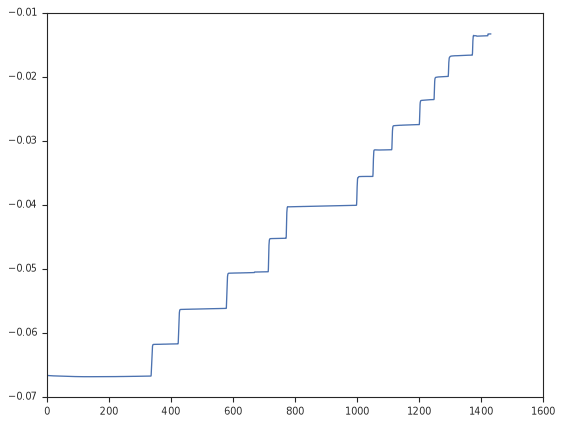

In [82]:
data = spinmob.data.load("10-22_hall.csv")
plt.plot(data["t2"], data["v1"])

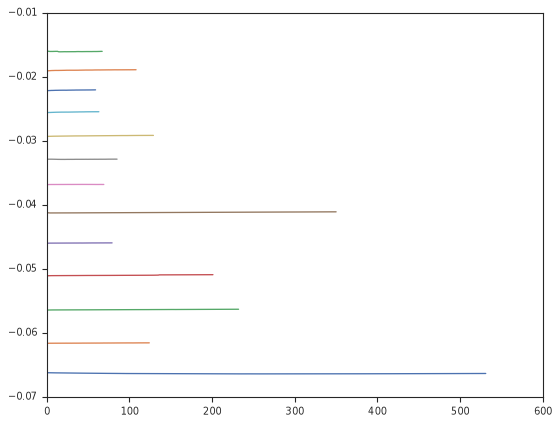

In [115]:
step = 0
buffer = []
tol = 0.0001
steps = []
in_jump = False

for i in range(0, len(data["v2"]) - 5):
    if data["v2"][i+5] - data["v2"][i] > tol and not in_jump:
        steps.append(buffer)
        buffer = []
        step += 1
        in_jump = True

    elif in_jump and data["v2"][i+5] - data["v2"][i] < tol:
        in_jump = False

    elif not in_jump:
        buffer.append(data["v2"][i])

for step in steps:
    plt.plot(np.arange(0, len(step)), step)

In [116]:
voltages = []
voltage_uncertainties = []

for step in steps:
    voltages.append(np.mean(step))
    voltage_uncertainties.append(np.std(step, ddof=1) / np.sqrt(len(steps)))

In [117]:
bfield = []

with open("b_field.csv", 'r', encoding='utf-8-sig') as file:
    reader = csv.reader(file)
    for line in reader:
        bfield.append(np.array(line, dtype=float))

field = []
field_uncertainties = []

for line in bfield:
    field.append(np.mean(line))
    field_uncertainties.append(np.std(line, ddof=1) / np.sqrt(len(line)))

In [5]:
model = lambda x, a, b: a * x + b
n = 5

fit = sp.optimize.curve_fit(
    model,
    field[:n],
    voltages[:n],
)

print(fit[0])

space = np.linspace(0, field[n])
vals = model(space, *fit[0])

plt.plot(field[:n], voltages[:n], marker="o")
plt.plot(space, vals)

NameError: name 'field' is not defined

# Band Gap Energy

In [46]:
data = spinmob.data.load("10-22_long_hot_2.csv")
T = data["T"] + 273.15
t = data["t9"]
offset = 0.5 * np.mean(data["v5"] - data["v6"])
data["v5"] -= offset
data["v6"] += offset
print("DC offset", offset)
t_res_uncertainty = np.abs(np.diff(data["T"]))
t_res_uncertainty = t_res_uncertainty[t_res_uncertainty != 0]
t_res_uncertainty = np.min(t_res_uncertainty) / np.sqrt(12)
print(t_res_uncertainty)

DC offset -0.002205592681304059
0.002251666049836344


In [47]:
# Estimate uncertainty introduced by linear approximation:
errs = []
for i in range(len(data["v5"]) - 2):
    t1, t2 = data["t5"][i], data["t5"][i+2]
    v1, v2 = data["v5"][i], data["v5"][i+2]
    t_curr = data["t5"][i+1]
    v_curr = data["v5"][i+1]

    s = (t_curr - t1) / (t2 - t1)
    v_est = (1 - s) * v1 + s * v2
    err = np.abs(v_est - v_curr)
    errs.append(err)

for i in range(len(data["v6"]) - 2):
    t1, t2 = data["t6"][i], data["t6"][i+2]
    v1, v2 = data["v6"][i], data["v6"][i+2]
    t_curr = data["t6"][i+1]
    v_curr = data["v6"][i+1]

    s = (t_curr - t1) / (t2 - t1)
    v_est = (1 - s) * v1 + s * v2
    err = np.abs(v_est - v_curr)
    errs.append(err)

lin_uncertainty = np.sqrt((1/len(errs)) * np.sum(np.array(errs)**2))
print("Uncertainty from time", lin_uncertainty)

# Estimate resolution uncertainty
res_uncertainty = np.abs(np.diff(data["v6"]))
res_uncertainty = res_uncertainty[res_uncertainty != 0]
res_uncertainty = np.min(res_uncertainty) / np.sqrt(12)
print("Uncertainty from resolution limit", res_uncertainty)

Uncertainty from time 0.007699243230759752
Uncertainty from resolution limit 1.443375672974256e-07


In [48]:
V = []
V_err = []

for i in range(len(T)-1):
    t_curr = t[i]
    v5_idx = np.where(data["t5"] < t_curr)[0][-1]
    v6_idx = np.where(data["t6"] < t_curr)[0][-1]
    t5_1, t5_2 = data["t5"][v5_idx], data["t5"][v5_idx + 1]
    t6_1, t6_2 = data["t6"][v6_idx], data["t6"][v6_idx + 1]
    v5_1, v5_2 = data["v5"][v5_idx], data["v5"][v5_idx + 1]
    v6_1, v6_2 = data["v6"][v6_idx], data["v6"][v6_idx + 1]

    s5 = (t_curr - t5_1) / (t5_2 - t5_1)
    s6 = (t_curr - t6_1) / (t6_2 - t6_1)

    v5 = (1 - s5) * v5_1 + s5 * v5_2
    v6 = (1 - s5) * v5_1 + s5 * v5_2

    v5_lin_unc = (1 - np.abs(2 * s5 - 1)) * lin_uncertainty
    v6_lin_unc = (1 - np.abs(2 * s6 - 1)) * lin_uncertainty

    v5_unc = np.sqrt(v5_lin_unc**2 + res_uncertainty**2)
    v6_unc = np.sqrt(v6_lin_unc**2 + res_uncertainty**2)

    v = ((v5 / v5_unc**2) + (v6 / v6_unc**2)) / (v5_unc ** -2 + v6_unc ** -2)
    err = (v5_unc ** -2 + v6_unc ** -2) ** -0.5

    V.append(v)
    V_err.append(err)

V = np.array(V)
V_err = np.array(V_err)
T = T[:-1]

In [49]:
t_uncs = []
for i in range(len(V) - 1):
    T0, V0 = T[i], V[i]
    T1, V1 = T[i-1], V[i-1]

    if np.abs(T1 - T0) < t_res_uncertainty:
        t_uncs.append(0.0)
        continue
    
    m = (V1 - V0) / (T1 - T0)
    dV = np.abs(t_res_uncertainty * m)
    t_uncs.append(dV)

t_uncs = np.array(t_uncs)
print(np.mean(t_uncs))
V = V[:-1]
T = T[:-1]
V_err = V_err[:-1]
V_err = np.sqrt(V_err**2 + t_uncs**2)

1.5827778639133865e-05


In [50]:
m = 1300
n = len(T)

V = V[m:n]
V_err = V_err[m:n]
T = T[m:n]

In [51]:
model = lambda x, a, b: a * x + b

fit = sp.optimize.curve_fit(
    model,
    1/T,
    np.log(V),
    sigma=V_err/V,
    absolute_sigma=True
)

uncertainties = np.sqrt(np.diag(fit[1]))
ans = fit[0][0] * 2 * sp.constants.Boltzmann * 6241509343260179000
uncertainty = uncertainties[0] * 2 * sp.constants.Boltzmann * 6241509343260179000
print(ans, uncertainty)
print(fit)

0.6010344152765313 0.0009179329198654019
(array([3487.35723169,  -10.58630381]), array([[ 2.83671747e+01, -7.70892864e-02],
       [-7.70892864e-02,  2.09502708e-04]]))


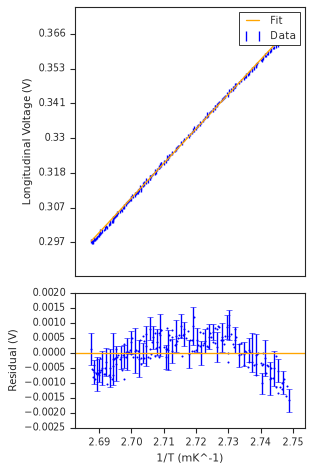

In [52]:
fig, ax = plt.subplots(2, 1, figsize=(4, 6), height_ratios=(2, 1))

ax[0].set_yscale("log", base=np.e)
ax[0].errorbar(1000/T, V, yerr=V_err, fmt="none", label="Data", capsize=0, color="blue")
space = np.linspace(np.min(1/T), np.max(1/T), 100)
vals = model(space, *fit[0])
ax[0].plot(1000 * space, np.exp(vals), color="orange", label="Fit")
ax[0].set_ylabel("Longitudinal Voltage (V)")
ax[0].set_xlim([np.min(1000/T) - 0.005, np.max(1000/T) + 0.005])
ax[0].set_ylim([np.min(V) - 0.01, np.max(V) + 0.01])
ax[0].set_xticks([])

ticks = np.geomspace(np.min(V), np.max(V), 7)
ax[0].set_yticks(ticks)
ax[0].set_yticklabels(np.round(ticks, 3))
ax[0].legend()

ax[1].set_xlabel("1/T (mK^-1)")
ax[1].set_ylabel("Residual (V)")
ax[1].set_xlim([np.min(1000/T) - 0.005, np.max(1000/T) + 0.005])
res = V - np.exp(model(1/T, *fit[0]))
plt.scatter(1/T, res)

T_idx = np.argsort(1/T)
ax[1].errorbar(1000/T[T_idx][::4], res[T_idx][::4], yerr=V_err[T_idx][::4], fmt="none", color="blue")
ax[1].scatter(1000/T, res, color="blue", s=1)
ax[1].axhline(0, color="orange")

fig.tight_layout()
plt.savefig("band_gap_energy.svg")

In [53]:
print(min(T), max(T))

363.8141 372.0875


In [54]:
res = np.log(V) - model(1/T, *fit[0])
unc = V_err / V

chi2 = np.sum((res / unc)**2)
red_chi2 = chi2 / (len(res) - 2)
print(red_chi2)

1.6006141866726198


# Hall Coefficient and Doping

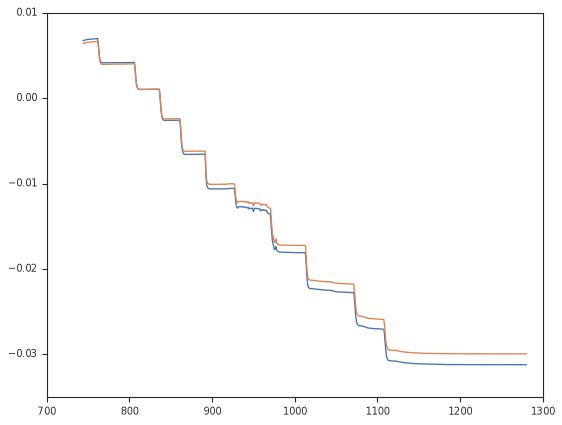

In [271]:
data = spinmob.data.load("10-29_hall.csv")
n = 1185
data["t1"] = data["t1"][n:]
data["t2"] = data["t2"][n:]
data["v1"] = data["v1"][n:]
data["v2"] = data["v2"][n:]
plt.plot(data["t1"], data["v1"])
plt.plot(data["t2"], data["v2"])

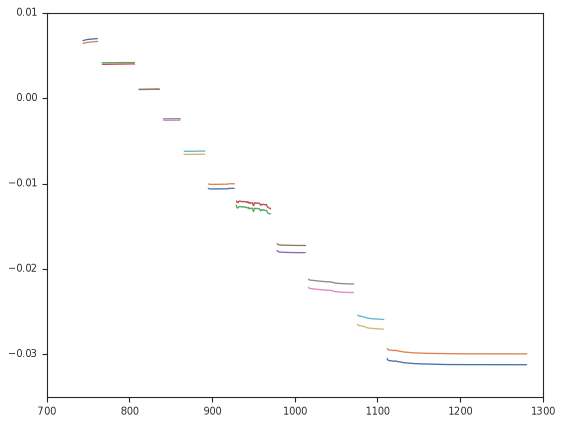

In [272]:
starts = (0,  37,  108, 155, 195, 242, 296, 375, 435, 530, 587)
stops =  (29, 100, 148, 188, 236, 293, 363, 430, 523, 581, 5000)

for i in range(len(starts)):
    plt.plot(data["t1"][starts[i]:stops[i]], data["v1"][starts[i]:stops[i]])
    plt.plot(data["t2"][starts[i]:stops[i]], data["v2"][starts[i]:stops[i]])

In [273]:
V1 = []
V1_unc = []
V2 = []
V2_unc = []

for i in range(len(starts)):
    v1 = data["v1"][starts[i]:stops[i]]
    v2 = data["v2"][starts[i]:stops[i]]
    V1.append(np.mean(v1))
    V2.append(np.mean(v2))
    V1_unc.append(np.std(v1, ddof=1) / np.sqrt(len(v1)))
    V2_unc.append(np.std(v2, ddof=1) / np.sqrt(len(v2)))

V1 = np.array(V1)
V2 = np.array(V2)
V1_unc = np.array(V1_unc)
V2_unc = np.array(V2_unc)

print(np.mean(V1_unc))

9.678338999860845e-06


In [274]:
res_uncertainty = np.abs(np.diff(data["v1"]))
res_uncertainty = res_uncertainty[res_uncertainty != 0]
res_uncertainty = np.min(res_uncertainty) / np.sqrt(12)
print(res_uncertainty)
V1_unc = np.sqrt(V1_unc**2 + res_uncertainty**2)
V2_unc = np.sqrt(V2_unc**2 + res_uncertainty**2)

2.886751345930985e-08


In [275]:
bfield = []

with open("Book2.csv", 'r', encoding='utf-8-sig') as file:
    reader = csv.reader(file)
    for line in reader:
        bfield.append(np.array(line, dtype=float))

field = []
field_unc = []

diffs = np.hstack([np.diff(line) for line in bfield])
b_res_uncertainty = np.abs(diffs)
b_res_uncertainty = b_res_uncertainty[b_res_uncertainty != 0]
b_res_uncertainty = np.min(b_res_uncertainty) / np.sqrt(12)

for line in bfield:
    field.append(np.mean(line))
    field_unc.append(np.std(line, ddof=1) / np.sqrt(len(line)))

field = np.array(field)
field_unc = np.array(field_unc)

print("B field statistical", np.mean(field_unc))
print("B field res", b_res_uncertainty)
field_unc = np.sqrt(field_unc**2 + b_res_uncertainty**2)

B field statistical 0.00047042029990152
B field res 2.8867513459481116e-05


In [276]:
calibration = []

with open("calibration_2.csv", 'r', encoding='utf-8-sig') as file:
    reader = csv.reader(file)
    for line in reader:
        calibration.append(np.array(line, dtype=float))

calibration = np.array(calibration)

In [277]:
errs = []
for i in range(len(calibration) - 2):
    v1, v2 = calibration[i, 0], calibration[i+2, 0]
    b1, b2 = calibration[i, 1], calibration[i+2, 1]
    v_curr = calibration[i+1, 0]
    b_curr = calibration[i+1, 1]

    s = (b_curr - b1) / (v2 - v1)
    b_est = (1 - s) * b1 + s * b2
    err = np.abs(b_est - b_curr)
    errs.append(err * 1e-3)

lin_unc = 0.5 * np.sqrt((1/len(errs)) * np.sum(np.array(errs)**2))
print(lin_unc)

0.002390571804027998


In [278]:
B = []
B_unc = []

for i in range(len(field)):
    v_curr = field[i] * 1e3
    v_unc_curr = field_unc[i] * 1e3

    if v_curr < 0:
        positive = False
        v_curr = np.abs(v_curr)
    else:
        positive = True
    v1_idx = np.where(calibration[:, 0] < v_curr)[0]

    if len(v1_idx) == 0:
        v1, v2 = calibration[0, 0], calibration[1, 0]
        b1, b2 = calibration[0, 1], calibration[1, 1]

    else:
        v1_idx = v1_idx[-1]
        v1, v2 = calibration[v1_idx, 0], calibration[v1_idx + 1, 0]
        b1, b2 = calibration[v1_idx, 1], calibration[v1_idx + 1, 1]

    s = (v_curr - v1) / (v2 - v1)
    s_err = (v_curr + v_unc_curr - v1) / (v2 - v1)

    b = (1 - s) * b1 + s * b2
    b_unc = np.abs(b - ((1 - s_err) * b1 + s_err * b2))
    b_lin_unc = (1- np.abs(2 * s - 1)) * lin_unc * 1e3
    b_unc = np.sqrt(b_unc ** 2  + b_lin_unc ** 2)

    B_unc.append(b_unc * 1e-3)
    if positive:
        B.append(b * 1e-3)
    else:
        B.append(-b * 1e-3)

B = np.array(B)
B_unc = np.array(B_unc)

In [279]:
V1_unc_new = []
V2_unc_new = []

for i in range(len(B)):
    if i == 0:
        m1 = (V1[1] - V1[0]) / (B[1] - B[0])
        m2 = (V2[1] - V2[0]) / (B[1] - B[0])
    else:
        m1 = (V1[i] - V1[i-1]) / (B[i] - B[i-1])
        m1 = (V2[i] - V2[i-1]) / (B[i] - B[i-1])

    print(B_unc[i])

    V1_unc_new.append(B_unc[i] * m1)
    V2_unc_new.append(B_unc[i] * m2)

V1_unc_new = np.array(V1_unc_new)
V2_unc_new = np.array(V2_unc_new)

V1_unc = np.sqrt(V1_unc**2 + V1_unc_new**2)
V2_unc = np.sqrt(V2_unc**2 + V2_unc_new**2)

0.002273933307483381
0.002964817906841747
0.0009295396959557885
0.0008365623096903378
0.002091612976121129
0.0026331065010285004
0.0008373212479141719
0.0019350439300897574
0.0007955766357932374
0.0021597392824024213
0.0021078638100294885


In [ ]:
model = lambda x, a, b: a * x + b

fit1 = sp.optimize.curve_fit(
    model,
    B,
    V1,
    sigma = V1_unc,
    absolute_sigma = True
)

fit2 = sp.optimize.curve_fit(
    model,
    B,
    V2,
    sigma = V2_unc,
    absolute_sigma = True
)

uncertainties1 = np.sqrt(np.diag(fit1[1]))
uncertainties2 = np.sqrt(np.diag(fit2[1]))

In [ ]:
h = 1e-2 * 453 / 1475
h_unc = 1e-3 * 10 * 4 / 1475

I = 0.010
I_unc = 0.01 * I

R1 = fit1[0][0] * h / I
R2 = fit2[0][0] * h / I

R1_unc = R1 * np.sqrt((uncertainties1[0] / fit1[0][0])**2 + (h_unc / h)**2 + (I_unc / I)**2)
R2_unc = R2 * np.sqrt((uncertainties2[0] / fit2[0][0])**2 + (h_unc / h)**2 + (I_unc / I)**2)

R = (R1 + R2) / 2
R_unc = np.sqrt(R1_unc**2 + R2_unc**2) / 2
print(R, R_unc)

3.0711864406779665 0.02711864406779661
0.03839183391376884 0.0003772100378052701


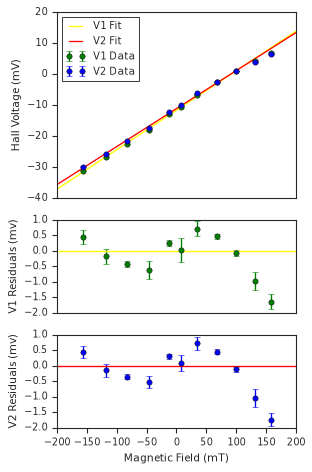

In [281]:
fig, ax = plt.subplots(3, 1, figsize=(4, 6), height_ratios=(2, 1, 1))

space = np.linspace(-0.2, 0.2, 100)
vals1 = model(space, *fit1[0])
vals2 = model(space, *fit2[0])

ax[0].errorbar(B*1e3, V1*1e3, yerr=V1_unc*1e3, fmt='o', color='green', label="V1 Data")
ax[0].errorbar(B*1e3, V2*1e3, yerr=V2_unc*1e3, fmt='o', color='blue', label="V2 Data")
ax[0].plot(space*1e3, vals1*1e3, color="yellow", label="V1 Fit")
ax[0].plot(space*1e3, vals2*1e3, color="red", label="V2 Fit")
ax[0].set_ylabel("Hall Voltage (mV)")
ax[0].legend(loc="upper left")
ax[2].set_xlabel("Magnetic Field (mT)")
ax[0].set_xticks([])
ax[0].set_xlim([-200, 200])

res1 = V1 - model(B, *fit1[0])
ax[1].errorbar(B*1e3, res1*1e3, yerr=V1_unc*1e3, fmt='o', color='green')
ax[1].axhline(0, color="yellow")
ax[1].set_xlim([-200, 200])
ax[1].set_xticks([])
ax[1].set_ylabel("V1 Residuals (mv)")

res2 = V2 - model(B, *fit2[0])
ax[2].errorbar(B*1e3, res2*1e3, yerr=V2_unc*1e3, fmt='o', color='blue')
ax[2].axhline(0, color="red")
ax[2].set_xlim([-200, 200])
ax[2].set_ylabel("V2 Residuals (mv)")


fig.tight_layout()
plt.savefig("hall_coefficient.svg")

In [282]:
chi21 = np.sum((res1 / V1_unc)**2)
red_chi21 = chi21 / (len(res1) - 2)
print(red_chi21)

chi22 = np.sum((res2 / V2_unc)**2)
red_chi22 = chi22 / (len(res2) - 2)
print(red_chi21)

15.046440959506713
15.046440959506713
